# EDA: Customer 360 sources
Goal: find every data-quality issue in the three sources **before** writing the pipeline, and decide per issue whether it can be imputed, fixed, or must be quarantined.

Sources: `crm_customers.json` (CRM), `orders.csv` (Order Management), `support_tickets.xml` (Support).

In [1]:
import json, re
import xml.etree.ElementTree as ET
import duckdb, pandas as pd
from email_validator import validate_email, EmailNotValidError
pd.set_option('display.width', 140)
DATA = '../DE-Customer360'
con = duckdb.connect()

## 1. Load each source as-is (raw)

In [2]:
# DuckDB reads JSON and CSV natively. all_varchar keeps raw values untouched so we can see bad ones.
crm = con.sql(f"SELECT * FROM read_json('{DATA}/crm_customers.json', format='array', columns={{'customer_id':'VARCHAR','name':'VARCHAR','email':'VARCHAR','city':'VARCHAR','registration_date':'VARCHAR'}})").df()
orders = con.sql(f"SELECT * FROM read_csv('{DATA}/orders.csv', header=true, all_varchar=true)").df()
# DuckDB has no XML reader, so parse with the stdlib and hand a DataFrame to DuckDB.
root = ET.parse(f'{DATA}/support_tickets.xml').getroot()
support = pd.DataFrame([{ch.tag: ch.text for ch in c} for c in root])
for name, df in [('crm', crm), ('orders', orders), ('support', support)]:
    print(f'{name:8} rows={len(df):4}  cols={list(df.columns)}')

crm      rows= 501  cols=['customer_id', 'name', 'email', 'city', 'registration_date']
orders   rows= 500  cols=['cust_id', 'total_orders', 'lifetime_value', 'last_order_date']
support  rows= 500  cols=['customerId', 'tickets', 'lastTicketDate']


## 2. Missing values per column

In [3]:
def missing(df):
    return df.apply(lambda s: s.isna().sum() + (s.astype(str).str.strip() == '').sum())
for name, df in [('crm', crm), ('orders', orders), ('support', support)]:
    m = missing(df); print(f'{name:8}', m[m > 0].to_dict() or 'no missing values')

crm      no missing values
orders   {'total_orders': 1}
support  {'customerId': 1}


In [4]:
display(orders[orders.total_orders.isna() | (orders.total_orders.astype(str).str.strip()=='')])
display(support[support.customerId.isna()])

,cust_id,total_orders,lifetime_value,last_order_date
309,C0310,NaN,122109,2026-05-17


,customerId,tickets,lastTicketDate
449,NaN,8,2026-07-03


## 3. Customer ID validity (`^C\\d{4}$`)

In [5]:
pat = re.compile(r'^C\d{4}$')
for name, df, col in [('crm', crm, 'customer_id'), ('orders', orders, 'cust_id'), ('support', support, 'customerId')]:
    bad = df[~df[col].fillna('').str.match(pat)]
    print(f'{name}: {len(bad)} invalid IDs'); 
    if len(bad): display(bad)

crm: 0 invalid IDs
orders: 0 invalid IDs
support: 1 invalid IDs


,customerId,tickets,lastTicketDate
449,NaN,8,2026-07-03


## 4. Duplicates: exact copies vs same ID with different content

In [6]:
crm['_row_num'] = range(1, len(crm) + 1)      # stands in for ingestion order
biz = ['customer_id','name','email','city','registration_date']
crm['_record_hash'] = pd.util.hash_pandas_object(crm[biz], index=False)
g = crm.groupby('customer_id').agg(n=('customer_id','size'), versions=('_record_hash','nunique'))
dups = g[g.n > 1]
print('IDs appearing more than once:', len(dups)); display(dups)
display(crm[crm.customer_id.isin(dups.index)])
print('orders dup IDs:', orders.cust_id.duplicated().sum(), '| support dup IDs:', support.customerId.dropna().duplicated().sum())

IDs appearing more than once: 1


,n,versions
customer_id,,
C0105,2,1


,customer_id,name,email,city,registration_date,_row_num,_record_hash
104,C0105,Vikram Jain 105,user105@example.com,Hyderabad,2025-06-02,105,9627074660829981950
500,C0105,Vikram Jain 105,user105@example.com,Hyderabad,2025-06-02,501,9627074660829981950


orders dup IDs: 0 | support dup IDs: 0


## 5. Email validity: regex vs `email-validator`

In [7]:
regex = re.compile(r'^[^@\s]+@[^@\s]+\.[^@\s]+$')
def ev(e):
    try: validate_email(e, check_deliverability=False); return True
    except EmailNotValidError: return False
crm['email_regex_ok'] = crm.email.str.match(regex)
crm['email_lib_ok'] = crm.email.map(ev)
print('domains:', crm.email.str.split('@').str[-1].value_counts().to_dict())
display(crm[~crm.email_regex_ok | ~crm.email_lib_ok][['customer_id','email','email_regex_ok','email_lib_ok']])
print('regex and library disagree on', (crm.email_regex_ok != crm.email_lib_ok).sum(), 'rows')

domains: {'example.com': 498, 'user125example.com': 1, 'user250example.com': 1, 'user375example.com': 1}


,customer_id,email,email_regex_ok,email_lib_ok
124,C0125,user125example.com,False,False
249,C0250,user250example.com,False,False
374,C0375,user375example.com,False,False


regex and library disagree on 0 rows


## 6. Numeric ranges: negative revenue, order counts, tickets

In [8]:
o = orders.assign(total_orders=pd.to_numeric(orders.total_orders, errors='coerce'),
                  lifetime_value=pd.to_numeric(orders.lifetime_value, errors='coerce'))
s = support.assign(tickets=pd.to_numeric(support.tickets, errors='coerce'))
display(o.describe().T); display(s.describe().T)
display(o[o.lifetime_value < 0])

,count,mean,std,min,25%,50%,75%,max
total_orders,499.0,15.468938,8.535335,1.0,8.0,15.0,23.00,30.0
lifetime_value,500.0,129154.802000,66500.570029,-5000.0,75343.0,130281.5,181150.25,249919.0


,count,mean,std,min,25%,50%,75%,max
tickets,500.0,6.16,3.841864,0.0,3.0,6.0,10.0,12.0


,cust_id,total_orders,lifetime_value,last_order_date
419,C0420,11.0,-5000,2026-04-28


## 7. Dates: parseable, plausible ranges

In [9]:
for name, df, col in [('crm', crm, 'registration_date'), ('orders', orders, 'last_order_date'), ('support', support, 'lastTicketDate')]:
    d = pd.to_datetime(df[col], format='%Y-%m-%d', errors='coerce')
    print(f'{name:8} {col:18} unparseable={d.isna().sum()}  min={d.min().date()}  max={d.max().date()}')
# Logical check: no order before the customer registered
m = crm.drop_duplicates('customer_id').merge(o, left_on='customer_id', right_on='cust_id')
print('orders dated before registration:', (pd.to_datetime(m.last_order_date) < pd.to_datetime(m.registration_date)).sum())

crm      registration_date  unparseable=0  min=2024-01-02  max=2025-11-28
orders   last_order_date    unparseable=0  min=2026-01-01  max=2026-10-28
support  lastTicketDate     unparseable=0  min=2026-01-01  max=2026-10-28
orders dated before registration: 0


## 8. Cross-source coverage (who is in which system)

In [10]:
A, B, Cs = set(crm.customer_id), set(orders.cust_id), set(support.customerId.dropna())
print('CRM only / not in orders:', sorted(A - B)); print('CRM not in support:', sorted(A - Cs))
print('orders not in CRM:', sorted(B - A)); print('support not in CRM:', sorted(Cs - A))

CRM only / not in orders: []
CRM not in support: ['C0450']
orders not in CRM: []
support not in CRM: []


## 9. Can the missing values be imputed?

### 9a. `total_orders` for C0310: is it predictable from lifetime value?

corr(total_orders, lifetime_value) = 0.003


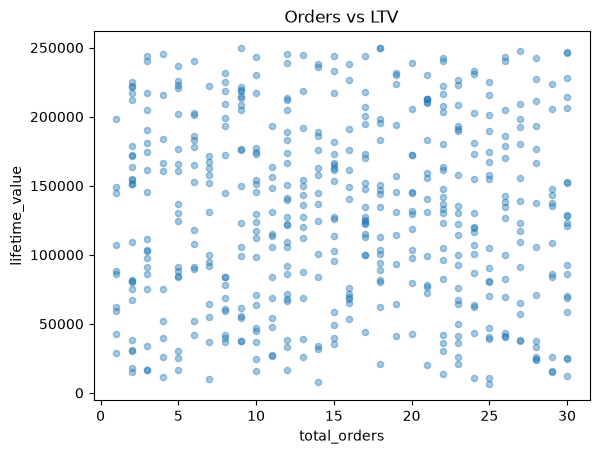

In [11]:
clean = o.dropna().query('lifetime_value >= 0')
print('corr(total_orders, lifetime_value) =', round(clean.total_orders.corr(clean.lifetime_value), 3))
clean.plot.scatter(x='total_orders', y='lifetime_value', alpha=.4, title='Orders vs LTV');

**Result:** correlation ≈ 0 means LTV carries no information about order count, so regression or KNN imputation would just reproduce the median. With 1 missing value out of 500, NULL plus a flag is the honest choice.

### 9b. The blank support customerId: can we infer it?

In [12]:
idx = support.index[support.customerId.isna()][0]
print('blank-ID record position:', idx, '| neighbours:', support.customerId.iloc[idx-1], support.customerId.iloc[idx+1])
print('CRM customer missing from support:', sorted(A - Cs))

blank-ID record position: 449 | neighbours: C0449 C0451
CRM customer missing from support: ['C0450']


## 11. Deep dive: cross-field and business-impact checks (the easy-to-miss ones)

In [13]:
s2 = s.copy()
print('tickets = 0 but a lastTicketDate exists:', ((s2.tickets == 0) & s2.lastTicketDate.notna()).sum())
print('same email on >1 row:', crm.email.str.lower().duplicated().sum(), '(the C0105 copy; a check that would also catch one person under two IDs)')
print('row position of duplicate copy:', crm[crm.customer_id.duplicated()]._row_num.tolist(), 'of', len(crm), '-> appended at the end, like a re-loaded batch')
print('orders.csv uses CRLF line endings:', open(f'{DATA}/orders.csv','rb').read().count(b'\r\n') > 0)
top10 = o.query('lifetime_value >= 0').nlargest(10, 'lifetime_value')
print('top-10 customers with invalid email:', sorted(set(top10.cust_id) & set(crm[~crm.email_lib_ok].customer_id)))
valid = s2[s2.customerId.notna()]
print('customers with > 5 tickets:', (valid.tickets > 5).sum(), 'of', len(valid), '(269 if the orphan record is C0450)')
aov = (o.lifetime_value / o.total_orders).dropna(); print('avg order value range:', round(aov[aov>0].min()), '-', round(aov.max()))

tickets = 0 but a lastTicketDate exists: 35
same email on >1 row: 1 (the C0105 copy; a check that would also catch one person under two IDs)
row position of duplicate copy: [501] of 501 -> appended at the end, like a re-loaded batch
orders.csv uses CRLF line endings: True
top-10 customers with invalid email: ['C0250']
customers with > 5 tickets: 268 of 499 (269 if the orphan record is C0450)
avg order value range: 267 - 198099


**Why these matter**
- **35 customers have 0 tickets but a last-ticket date.** Every column passes on its own; only a cross-field rule catches this. Pipeline: `ticket_date_without_tickets` warning, values kept.
- **C0250 is #10 by revenue and has an invalid email.** Quarantining the whole row for a bad email would silently change the Top-10 report. This is evidence for nulling the field instead of rejecting the row.
- **The duplicate copy is the last row of the file**, the signature of a batch loaded twice. That supports dedupe by ingestion order.
- **orders.csv has Windows line endings.** Harmless for DuckDB, but a naive line splitter would leave `\r` on the last column.
- **More than half the customers have > 5 tickets**, so that threshold isn't selective. Worth raising with the business (it's configurable).

## 10. Findings → pipeline decisions

| # | Source | Issue | Rows | Imputable? | Action in pipeline |
|---|---|---|---|---|---|
| 1 | CRM | Exact duplicate record (C0105 ×2, identical hash) | 1 extra | n/a | Keep first by ingestion order, quarantine the copy as `duplicate`, reference the kept row |
| 2 | CRM | Email without `@` (C0125, C0250, C0375) | 3 | No: an email can't be guessed | Keep customer, set `email` to NULL, keep raw value in quarantine, flag `invalid_email` |
| 3 | Orders | `total_orders` empty (C0310) | 1 | **No.** corr(orders, LTV) = 0.003, so a model would just return the median (15) and invent a number | NULL + flag `missing_total_orders`. Imputation plan documented in README (median/KNN/MICE/MissForest when real signal exists) |
| 4 | Orders | `lifetime_value = -5000` (C0420) | 1 | No: could be a refund or a typo, sign unknown | NULL + flag `negative_revenue`, excluded from revenue maths, raw value kept |
| 5 | Support | Blank `customerId` (8 tickets) | 1 | Inferable by position/elimination (→ C0450), but not safe to auto-apply | Quarantine as `invalid_customer_id` with a `suggested_customer_id` hint for manual review. C0450 gets `in_support = false` |

No orphans, no unparseable dates, and no order before registration. Everything else is clean.